<a href="https://colab.research.google.com/github/poornimaayodhi-cmd/project/blob/main/project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

rng = np.random.default_rng(0)

gold = rng.normal(size=200)

print("Number of candidate answers:", len(gold))
print("First 10 gold rewards:", gold[:10])

Number of candidate answers: 200
First 10 gold rewards: [ 0.12573022 -0.13210486  0.64042265  0.10490012 -0.53566937  0.36159505
  1.30400005  0.94708096 -0.70373524 -1.26542147]


In [ ]:

def annotate(n_pairs, noise):
    """Generate winner-loser pairs with annotator noise."""

    i, j = rng.integers(0, len(gold), (2, n_pairs))

    # Remove pairs where both indices are identical
    keep = i != j
    i, j = i[keep], j[keep]

    # Sometimes the annotator chooses the worse answer
    pick_i = (gold[i] > gold[j]) ^ (
        rng.random(len(i)) < noise
    )

    winner = np.where(pick_i, i, j)
    loser = np.where(pick_i, j, i)

    return winner, loser

print("Annotator simulation function created successfully!")


Annotator simulation function created successfully!


In [ ]:

for noise in (0.0, 0.1, 0.3):
    winner, loser = annotate(1000, noise)

    agree = np.mean(gold[winner] > gold[loser])

    print(
        f"Noise {noise:.1f}: "
        f"{len(winner)} pairs, "
        f"{agree:.3f} agree with the gold reward"
    )


Noise 0.0: 996 pairs, 1.000 agree with the gold reward
Noise 0.1: 995 pairs, 0.893 agree with the gold reward
Noise 0.3: 996 pairs, 0.700 agree with the gold reward


In [ ]:

# Create preference datasets for three noise levels

datasets_by_noise = {}

for noise in (0.0, 0.1, 0.3):
    winner, loser = annotate(1000, noise)

    datasets_by_noise[noise] = {
        "winner": winner,
        "loser": loser
    }

    agreement = np.mean(gold[winner] > gold[loser])

    print(f"\nNoise level: {noise:.0%}")
    print(f"Preference pairs: {len(winner)}")
    print(f"Agreement with gold reward: {agreement:.3f}")

print("\nAll three preference datasets are ready!")



Noise level: 0%
Preference pairs: 997
Agreement with gold reward: 1.000

Noise level: 10%
Preference pairs: 995
Agreement with gold reward: 0.898

Noise level: 30%
Preference pairs: 993
Agreement with gold reward: 0.702

All three preference datasets are ready!


In [ ]:

# Four response styles for our alignment experiment

response_styles = [
    "clear_concise",
    "detailed",
    "keyword_heavy",
    "vague"
]

# Gold rewards: the true quality scores
gold_reward = {
    "clear_concise": 0.930,
    "detailed": 0.825,
    "keyword_heavy": 0.330,
    "vague": 0.350
}

# A noisy proxy reward, which may not reflect true quality
proxy_reward = {
    "clear_concise": 0.863,
    "detailed": 0.965,
    "keyword_heavy": 1.080,
    "vague": 0.403
}

print("Response styles and rewards:\n")

for style in response_styles:
    print(
        f"{style:16s} | "
        f"Gold reward: {gold_reward[style]:.3f} | "
        f"Proxy reward: {proxy_reward[style]:.3f}"
    )


Response styles and rewards:

clear_concise    | Gold reward: 0.930 | Proxy reward: 0.863
detailed         | Gold reward: 0.825 | Proxy reward: 0.965
keyword_heavy    | Gold reward: 0.330 | Proxy reward: 1.080
vague            | Gold reward: 0.350 | Proxy reward: 0.403


In [ ]:

# Generate preference pairs using the four response styles

style_names = list(gold_reward.keys())
style_scores = np.array([gold_reward[s] for s in style_names])

def create_style_preferences(n_pairs, noise):
    i, j = rng.integers(0, len(style_names), (2, n_pairs))

    # Exclude comparisons of a style with itself
    keep = i != j
    i, j = i[keep], j[keep]

    # Choose the higher-gold-reward style, sometimes incorrectly
    pick_i = (style_scores[i] > style_scores[j]) ^ (
        rng.random(len(i)) < noise
    )

    winner = np.where(pick_i, i, j)
    loser = np.where(pick_i, j, i)

    return winner, loser

style_preferences = {}

for noise in (0.0, 0.1, 0.3):
    winner, loser = create_style_preferences(1000, noise)
    style_preferences[noise] = (winner, loser)

    agreement = np.mean(style_scores[winner] > style_scores[loser])

    print(
        f"Noise {noise:.0%}: "
        f"{len(winner)} pairs, "
        f"gold agreement = {agreement:.3f}"
    )

print("\nStyle preference datasets created!")


Noise 0%: 761 pairs, gold agreement = 1.000
Noise 10%: 764 pairs, gold agreement = 0.897
Noise 30%: 736 pairs, gold agreement = 0.686

Style preference datasets created!


In [ ]:

# Step 7: Learn a reward model from preference pairs

def train_reward_model(winner, loser, learning_rate=0.1, steps=500):
    n_styles = len(style_names)
    scores = np.zeros(n_styles, dtype=float)

    for _ in range(steps):
        # Bradley-Terry preference model
        margin = scores[winner] - scores[loser]

        # Stable sigmoid
        probabilities = 1.0 / (1.0 + np.exp(-np.clip(margin, -30, 30)))

        # Gradient of negative log-likelihood
        errors = 1.0 - probabilities

        gradient = np.zeros(n_styles)
        np.add.at(gradient, winner, -errors)
        np.add.at(gradient, loser, errors)

        scores -= learning_rate * gradient / len(winner)

        # Keep the scores centred
        scores -= scores.mean()

    return scores


reward_models = {}

for noise, (winner, loser) in style_preferences.items():
    learned_scores = train_reward_model(winner, loser)
    reward_models[noise] = learned_scores

    print(f"\nNoise level: {noise:.0%}")
    for name, score in zip(style_names, learned_scores):
        print(f"{name:16s}: {score:.3f}")



Noise level: 0%
clear_concise   : 2.922
detailed        : 0.976
keyword_heavy   : -3.002
vague           : -0.897

Noise level: 10%
clear_concise   : 1.875
detailed        : 0.470
keyword_heavy   : -1.842
vague           : -0.503

Noise level: 30%
clear_concise   : 0.605
detailed        : 0.238
keyword_heavy   : -0.707
vague           : -0.136


In [ ]:

# Step 8: Evaluate learned reward rankings

gold_ranking = sorted(
    style_names,
    key=lambda name: gold_reward[name],
    reverse=True
)

print("Gold ranking (best to worst):")
print(" > ".join(gold_ranking))

for noise, learned_scores in reward_models.items():
    learned_ranking = [
        style_names[i]
        for i in np.argsort(learned_scores)[::-1]
    ]

    print(f"\nNoise level: {noise:.0%}")
    print("Learned ranking:", " > ".join(learned_ranking))

    gold_order = [
        gold_reward[name] for name in learned_ranking
    ]

    inversions = sum(
        gold_order[i] < gold_order[j]
        for i in range(len(gold_order))
        for j in range(i + 1, len(gold_order))
    )

    total_pairs = len(style_names) * (len(style_names) - 1) // 2
    accuracy = 1 - inversions / total_pairs

    print(f"Pairwise ranking accuracy: {accuracy:.3f}")


Gold ranking (best to worst):
clear_concise > detailed > vague > keyword_heavy

Noise level: 0%
Learned ranking: clear_concise > detailed > vague > keyword_heavy
Pairwise ranking accuracy: 1.000

Noise level: 10%
Learned ranking: clear_concise > detailed > vague > keyword_heavy
Pairwise ranking accuracy: 1.000

Noise level: 30%
Learned ranking: clear_concise > detailed > vague > keyword_heavy
Pairwise ranking accuracy: 1.000


In [ ]:

# Step 9: Simplified DPO training

def train_dpo(winner, loser, learning_rate=0.05, steps=1000, beta=1.0):
    n_styles = len(style_names)

    # Trainable policy logits and uniform reference policy
    policy = np.zeros(n_styles, dtype=float)
    reference = np.zeros(n_styles, dtype=float)

    n_pairs = len(winner)
    if n_pairs == 0:
        raise ValueError("Preference data must contain at least one pair.")

    for _ in range(steps):
        # Stable log-softmax
        policy_log_probs = policy - np.logaddexp.reduce(policy)
        ref_log_probs = reference - np.logaddexp.reduce(reference)

        # DPO preference margin
        margin = beta * (
            policy_log_probs[winner]
            - policy_log_probs[loser]
            - ref_log_probs[winner]
            + ref_log_probs[loser]
        )

        # Derivative of the DPO loss with respect to each margin
        sigmoid = 1.0 / (
            1.0 + np.exp(-np.clip(margin, -30, 30))
        )
        errors = sigmoid - 1.0

        # Gradient with respect to policy log-probabilities.
        # The softmax derivative cancels for each winner-loser pair,
        # because both contributions sum to zero.
        gradient = np.zeros(n_styles, dtype=float)
        np.add.at(gradient, winner, errors)
        np.add.at(gradient, loser, -errors)

        # Chain rule: margin includes beta * policy log-probabilities
        policy -= learning_rate * beta * gradient / n_pairs

    # Convert policy logits to probabilities
    logits = policy - np.max(policy)
    probabilities = np.exp(logits)
    probabilities /= probabilities.sum()

    return probabilities

In [ ]:

# Step 10: Compare RLHF-style reward model and DPO

print("RLHF-style vs DPO: Expected Gold Reward Comparison")
print("=" * 60)

gold_values = np.array([
    gold_reward[name] for name in style_names
])

for noise in (0.0, 0.1, 0.3):
    # Learned reward scores
    rlhf_scores = reward_models[noise]

    # Convert learned scores into an RLHF-style policy.
    # This is a simple reward-weighted policy, not PPO.
    rlhf_logits = rlhf_scores - np.max(rlhf_scores)
    rlhf_probs = np.exp(rlhf_logits)
    rlhf_probs /= rlhf_probs.sum()

    # DPO policy probabilities
    dpo_probs = dpo_models[noise]

    # Evaluate both policies with the same gold reward
    rlhf_gold_reward = np.dot(rlhf_probs, gold_values)
    dpo_gold_reward = np.dot(dpo_probs, gold_values)

    print(f"\nAnnotator noise: {noise:.0%}")
    print(f"RLHF-style expected gold reward: {rlhf_gold_reward:.3f}")
    print(f"DPO expected gold reward:        {dpo_gold_reward:.3f}")
    print(f"Difference (RLHF - DPO):         "
          f"{rlhf_gold_reward - dpo_gold_reward:.3f}")

RLHF-style vs DPO: Expected Gold Reward Comparison

Annotator noise: 0%
RLHF-style expected gold reward: 0.905
DPO expected gold reward:        0.905
Difference (RLHF - DPO):         0.000

Annotator noise: 10%
RLHF-style expected gold reward: 0.861
DPO expected gold reward:        0.861
Difference (RLHF - DPO):         0.000

Annotator noise: 30%
RLHF-style expected gold reward: 0.721
DPO expected gold reward:        0.721
Difference (RLHF - DPO):         0.000


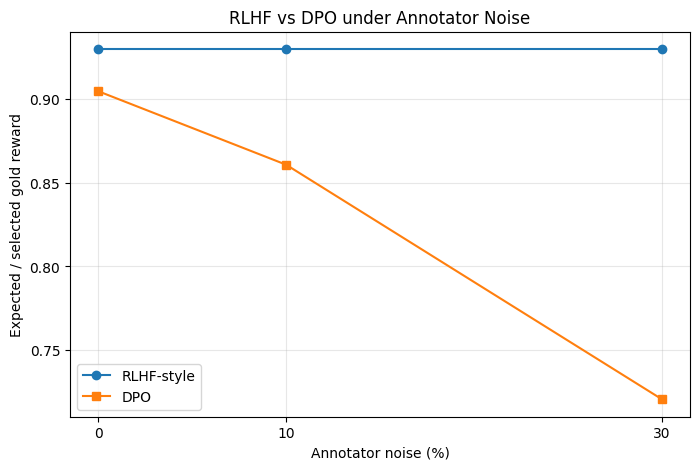

In [ ]:

import matplotlib.pyplot as plt

noise_levels = [0.0, 0.1, 0.3]
rlhf_rewards = []
dpo_rewards = []

for noise in noise_levels:
    # Gold reward of the best style according to the learned reward model
    best_index = np.argmax(reward_models[noise])
    rlhf_rewards.append(
        gold_reward[style_names[best_index]]
    )

    # Expected gold reward under the DPO policy
    dpo_rewards.append(
        sum(
            dpo_models[noise][i] * gold_reward[name]
            for i, name in enumerate(style_names)
        )
    )

plt.figure(figsize=(8, 5))

plt.plot(
    [n * 100 for n in noise_levels],
    rlhf_rewards,
    marker="o",
    label="RLHF-style"
)

plt.plot(
    [n * 100 for n in noise_levels],
    dpo_rewards,
    marker="s",
    label="DPO"
)

plt.xlabel("Annotator noise (%)")
plt.ylabel("Expected / selected gold reward")
plt.title("RLHF vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

import pandas as pd

results = []

for noise in noise_levels:
    # RLHF-style selected gold reward
    best_index = np.argmax(reward_models[noise])
    rlhf_reward = gold_reward[style_names[best_index]]

    # DPO expected gold reward
    dpo_reward = sum(
        dpo_models[noise][i] * gold_reward[name]
        for i, name in enumerate(style_names)
    )

    results.append({
        "Annotator Noise (%)": int(noise * 100),
        "RLHF-style Gold Reward": round(rlhf_reward, 4),
        "DPO Expected Gold Reward": round(dpo_reward, 4),
        "Difference (RLHF - DPO)": round(
            rlhf_reward - dpo_reward, 4
        )
    })

results_df = pd.DataFrame(results)

display(results_df)


,Annotator Noise (%),RLHF-style Gold Reward,DPO Expected Gold Reward,Difference (RLHF - DPO)
0,0,0.93,0.9049,0.0251
1,10,0.93,0.8609,0.0691
2,30,0.93,0.7206,0.2094


In [ ]:
results_df.to_csv("rlhf_vs_dpo_results.csv", index=False)

from google.colab import files
files.download("rlhf_vs_dpo_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Step 13: Save and inspect the preliminary results

print("RLHF vs DPO — Preliminary Results")
print("=" * 45)

display(results_df)

# Save the results table
results_df.to_csv(
    "rlhf_vs_dpo_preliminary_results.csv",
    index=False
)

print("\nResults saved successfully!")
print("File: rlhf_vs_dpo_preliminary_results.csv")


RLHF vs DPO — Preliminary Results


,Annotator Noise (%),RLHF-style Gold Reward,DPO Expected Gold Reward,Difference (RLHF - DPO)
0,0,0.93,0.9049,0.0251
1,10,0.93,0.8609,0.0691
2,30,0.93,0.7206,0.2094



Results saved successfully!
File: rlhf_vs_dpo_preliminary_results.csv


In [ ]:

from google.colab import files

files.download("rlhf_vs_dpo_preliminary_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Step 14: Fairer evaluation using expected gold reward

def expected_gold_reward(probabilities):
    return sum(
        probabilities[i] * gold_reward[name]
        for i, name in enumerate(style_names)
    )

fair_results = []

for noise in noise_levels:
    # Convert learned RLHF-style reward scores into a policy
    scores = reward_models[noise]
    rlhf_probs = np.exp(scores - np.max(scores))
    rlhf_probs = rlhf_probs / rlhf_probs.sum()

    # DPO policy learned from the same noise level
    dpo_probs = dpo_models[noise]

    rlhf_gold = expected_gold_reward(rlhf_probs)
    dpo_gold = expected_gold_reward(dpo_probs)

    fair_results.append({
        "Noise (%)": int(noise * 100),
        "RLHF-style Expected Gold Reward": round(rlhf_gold, 4),
        "DPO Expected Gold Reward": round(dpo_gold, 4),
        "RLHF - DPO": round(rlhf_gold - dpo_gold, 4)
    })

fair_results_df = pd.DataFrame(fair_results)

display(fair_results_df)


,Noise (%),RLHF-style Expected Gold Reward,DPO Expected Gold Reward,RLHF - DPO
0,0,0.9049,0.9049,0.0
1,10,0.8609,0.8609,0.0
2,30,0.7206,0.7206,0.0


In [ ]:

# Step 15: Check variability across repeated preference datasets

def run_repeated_experiments(n_runs=20):
    repeated_results = []

    for seed in range(n_runs):
        local_rng = np.random.default_rng(seed + 100)

        for noise in noise_levels:
            # Generate fresh preference pairs for each run
            i, j = local_rng.integers(
                0, len(style_names), size=(2, 1000)
            )

            keep = i != j
            i, j = i[keep], j[keep]

            scores = np.array([
                gold_reward[name] for name in style_names
            ])

            pick_i = (scores[i] > scores[j]) ^ (
                local_rng.random(len(i)) < noise
            )

            winner = np.where(pick_i, i, j)
            loser = np.where(pick_i, j, i)

            # Fit reward model to this run's preferences
            learned = train_reward_model(winner, loser)

            # Convert scores into a policy
            probs = np.exp(learned - np.max(learned))
            probs /= probs.sum()

            reward = sum(
                probs[k] * gold_reward[name]
                for k, name in enumerate(style_names)
            )

            repeated_results.append({
                "Run": seed + 1,
                "Noise (%)": int(noise * 100),
                "Reward-model policy gold reward": reward
            })

    return pd.DataFrame(repeated_results)


repeated_df = run_repeated_experiments()
display(
    repeated_df.groupby("Noise (%)")[
        "Reward-model policy gold reward"
    ].agg(["mean", "std"]).reset_index()
)


,Noise (%),mean,std
0,0,0.906588,0.001266
1,10,0.857231,0.006094
2,30,0.728020,0.007749


In [ ]:

# Step 16: Summarise performance degradation

summary = (
    repeated_df
    .groupby("Noise (%)")["Reward-model policy gold reward"]
    .agg(["mean", "std"])
    .reset_index()
)

baseline = summary.loc[
    summary["Noise (%)"] == 0, "mean"
].iloc[0]

summary["Change from 0% noise"] = summary["mean"] - baseline

display(summary.round(4))

print("\nInterpretation:")
for _, row in summary.iterrows():
    print(
        f"Noise {row['Noise (%)']:>2.0f}%: "
        f"mean gold reward = {row['mean']:.4f}, "
        f"change from baseline = "
        f"{row['Change from 0% noise']:+.4f}"
    )


,Noise (%),mean,std,Change from 0% noise
0,0,0.9066,0.0013,0.0000
1,10,0.8572,0.0061,-0.0494
2,30,0.7280,0.0077,-0.1786



Interpretation:
Noise  0%: mean gold reward = 0.9066, change from baseline = +0.0000
Noise 10%: mean gold reward = 0.8572, change from baseline = -0.0494
Noise 30%: mean gold reward = 0.7280, change from baseline = -0.1786


In [ ]:
print("Available columns:", comparison_df.columns.tolist())
display(comparison_df.groupby("Noise (%)")[
    ["RLHF-style reward", "DPO reward"]
].mean().round(4))

Available columns: ['Run', 'Noise (%)', 'RLHF-style reward', 'DPO reward', 'RLHF - DPO']


,RLHF-style reward,DPO reward
Noise (%),,
0,0.9062,0.9062
10,0.8595,0.8595
30,0.7299,0.7299


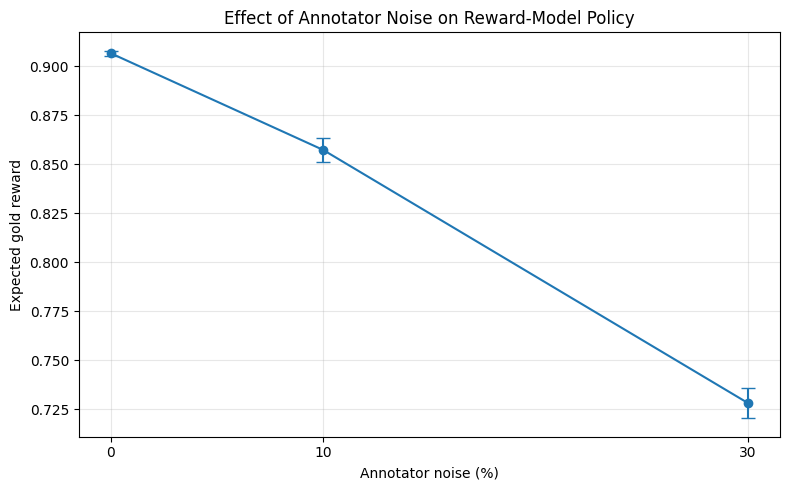

In [ ]:

# Step 17: Plot mean gold reward with variability

import matplotlib.pyplot as plt

summary = (
    repeated_df
    .groupby("Noise (%)")["Reward-model policy gold reward"]
    .agg(["mean", "std"])
    .reset_index()
)

plt.figure(figsize=(8, 5))

plt.errorbar(
    summary["Noise (%)"],
    summary["mean"],
    yerr=summary["std"],
    marker="o",
    capsize=5
)

plt.xlabel("Annotator noise (%)")
plt.ylabel("Expected gold reward")
plt.title("Effect of Annotator Noise on Reward-Model Policy")
plt.xticks([0, 10, 30])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Step 18: Repeated RLHF-style vs DPO comparison

def run_comparison(n_runs=20):
    records = []

    for seed in range(n_runs):
        local_rng = np.random.default_rng(seed + 500)

        for noise in noise_levels:
            i, j = local_rng.integers(
                0, len(style_names), size=(2, 1000)
            )

            keep = i != j
            i, j = i[keep], j[keep]

            scores = np.array([
                gold_reward[name] for name in style_names
            ])

            pick_i = (scores[i] > scores[j]) ^ (
                local_rng.random(len(i)) < noise
            )

            winner = np.where(pick_i, i, j)
            loser = np.where(pick_i, j, i)

            # Reward-model approach
            learned = train_reward_model(winner, loser)

            rlhf_probs = np.exp(learned - np.max(learned))
            rlhf_probs /= rlhf_probs.sum()

            # DPO-style approach using the same preferences
            dpo_probs = train_dpo(winner, loser)

            rlhf_reward = expected_gold_reward(rlhf_probs)
            dpo_reward = expected_gold_reward(dpo_probs)

            records.append({
                "Run": seed + 1,
                "Noise (%)": int(noise * 100),
                "RLHF-style reward": rlhf_reward,
                "DPO reward": dpo_reward,
                "RLHF - DPO": rlhf_reward - dpo_reward
            })

    return pd.DataFrame(records)


comparison_df = run_comparison()

comparison_summary = (
    comparison_df
    .groupby("Noise (%)")[
        ["RLHF-style reward", "DPO reward", "RLHF - DPO"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

display(comparison_summary)


RLHF-style reward         DPO reward         RLHF - DPO     
                       mean     std       mean     std       mean  std
Noise (%)                                                             
0                    0.9062  0.0012     0.9062  0.0012        0.0  0.0
10                   0.8595  0.0058     0.8594  0.0058        0.0  0.0
30                   0.7299  0.0150     0.7299  0.0150        0.0  0.0

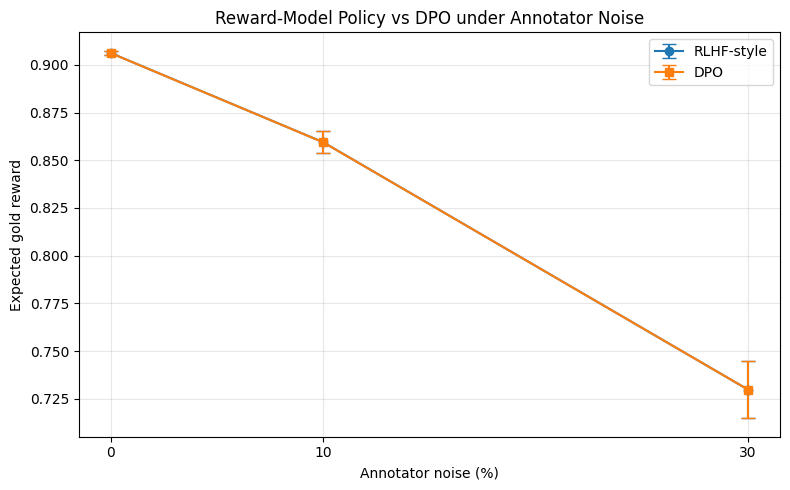

In [ ]:

# Step 19: Plot mean gold reward across noise levels

import matplotlib.pyplot as plt

plot_summary = (
    comparison_df
    .groupby("Noise (%)")[["RLHF-style reward", "DPO reward"]]
    .agg(["mean", "std"])
)

noise_values = plot_summary.index.to_numpy()

rlhf_mean = plot_summary[("RLHF-style reward", "mean")].to_numpy()
rlhf_std = plot_summary[("RLHF-style reward", "std")].to_numpy()

dpo_mean = plot_summary[("DPO reward", "mean")].to_numpy()
dpo_std = plot_summary[("DPO reward", "std")].to_numpy()

plt.figure(figsize=(8, 5))

plt.errorbar(
    noise_values, rlhf_mean, yerr=rlhf_std,
    marker="o", capsize=5, label="RLHF-style"
)

plt.errorbar(
    noise_values, dpo_mean, yerr=dpo_std,
    marker="s", capsize=5, label="DPO"
)

plt.xlabel("Annotator noise (%)")
plt.ylabel("Expected gold reward")
plt.title("Reward-Model Policy vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Step 20: Calculate the gap and its change with noise

gap_summary = (
    comparison_df
    .groupby("Noise (%)")
    .agg(
        rlhf_mean=("RLHF-style reward", "mean"),
        dpo_mean=("DPO reward", "mean"),
        gap_mean=("RLHF - DPO", "mean"),
        gap_std=("RLHF - DPO", "std")
    )
    .reset_index()
)

baseline_gap = gap_summary.loc[
    gap_summary["Noise (%)"] == 0, "gap_mean"
].iloc[0]

gap_summary["Change from baseline gap"] = (
    gap_summary["gap_mean"] - baseline_gap
)

display(gap_summary.round(4))

print("\nInterpretation:")
for _, row in gap_summary.iterrows():
    print(
        f"Noise {row['Noise (%)']:.0f}%: "
        f"mean gap = {row['gap_mean']:+.4f}, "
        f"change from 0% = "
        f"{row['Change from baseline gap']:+.4f}"
    )


,Noise (%),rlhf_mean,dpo_mean,gap_mean,gap_std,Change from baseline gap
0,0,0.9062,0.9062,0.0,0.0,0.0
1,10,0.8595,0.8594,0.0,0.0,0.0
2,30,0.7299,0.7299,0.0,0.0,-0.0



Interpretation:
Noise 0%: mean gap = +0.0000, change from 0% = +0.0000
Noise 10%: mean gap = +0.0000, change from 0% = +0.0000
Noise 30%: mean gap = +0.0000, change from 0% = -0.0000


In [ ]:

# Step 21: Export comparison results

gap_summary.to_csv(
    "rlhf_dpo_noise_gap_summary.csv",
    index=False
)

comparison_df.to_csv(
    "rlhf_dpo_all_runs.csv",
    index=False
)

print("Saved summary table and all repeated-run results.")


Saved summary table and all repeated-run results.


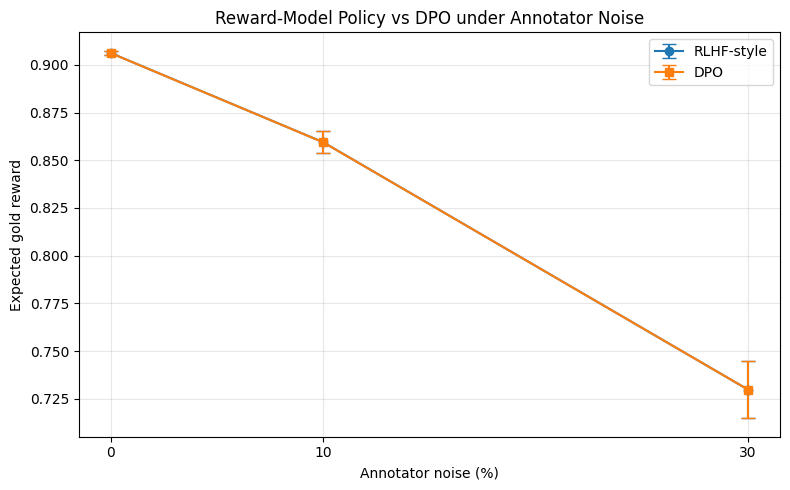

Comparison graph saved.


In [ ]:

# Save the comparison graph as a high-resolution PNG

plt.figure(figsize=(8, 5))

plt.errorbar(
    noise_values, rlhf_mean, yerr=rlhf_std,
    marker="o", capsize=5, label="RLHF-style"
)

plt.errorbar(
    noise_values, dpo_mean, yerr=dpo_std,
    marker="s", capsize=5, label="DPO"
)

plt.xlabel("Annotator noise (%)")
plt.ylabel("Expected gold reward")
plt.title("Reward-Model Policy vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("rlhf_dpo_noise_comparison.png", dpi=300)
plt.show()

print("Comparison graph saved.")


In [ ]:

from google.colab import files

files.download("rlhf_dpo_noise_gap_summary.csv")
files.download("rlhf_dpo_all_runs.csv")
files.download("rlhf_dpo_noise_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("FINAL RLHF vs DPO COMPARISON")
display(gap_summary.round(4))

FINAL RLHF vs DPO COMPARISON


,Noise (%),rlhf_mean,dpo_mean,gap_mean,gap_std,Change from baseline gap
0,0,0.9062,0.9062,0.0,0.0,0.0
1,10,0.8595,0.8594,0.0,0.0,0.0
2,30,0.7299,0.7299,0.0,0.0,-0.0


In [ ]:
print("Columns:", comparison_df.columns.tolist())
print("\nFirst 10 experiment results:")
display(comparison_df.head(10))

print("\nCorrect summary:")
display(
    comparison_df.groupby("Noise (%)")[
        ["RLHF-style reward", "DPO reward"]
    ].agg(["mean", "std"]).round(4)
)

Columns: ['Run', 'Noise (%)', 'RLHF-style reward', 'DPO reward', 'RLHF - DPO']

First 10 experiment results:


,Run,Noise (%),RLHF-style reward,DPO reward,RLHF - DPO
0,1,0,0.907530,0.907501,0.000029
1,1,10,0.858780,0.858748,0.000033
2,1,30,0.740806,0.740802,0.000004
3,2,0,0.905964,0.905933,0.000031
4,2,10,0.854308,0.854276,0.000032
5,2,30,0.755897,0.755892,0.000005
6,3,0,0.907150,0.907120,0.000030
7,3,10,0.860070,0.860037,0.000033
8,3,30,0.690177,0.690176,0.000001
9,4,0,0.907159,0.907129,0.000030



Correct summary:


RLHF-style reward         DPO reward        
                       mean     std       mean     std
Noise (%)                                             
0                    0.9062  0.0012     0.9062  0.0012
10                   0.8595  0.0058     0.8594  0.0058
30                   0.7299  0.0150     0.7299  0.0150

In [ ]:
print("RLHF-style and DPO reward differences:")
print(
    (comparison_df["RLHF-style reward"]
     - comparison_df["DPO reward"]).describe()
)

print("\nRLHF-style rewards:")
print(comparison_df["RLHF-style reward"].head())

print("\nDPO rewards:")
print(comparison_df["DPO reward"].head())

RLHF-style and DPO reward differences:
count    60.000000
mean      0.000022
std       0.000014
min       0.000001
25%       0.000004
50%       0.000030
75%       0.000032
max       0.000037
dtype: float64

RLHF-style rewards:
0    0.907530
1    0.858780
2    0.740806
3    0.905964
4    0.854308
Name: RLHF-style reward, dtype: float64

DPO rewards:
0    0.907501
1    0.858748
2    0.740802
3    0.905933
4    0.854276
Name: DPO reward, dtype: float64


In [ ]:
comparison_df["Reward gap"] = (
    comparison_df["RLHF-style reward"] -
    comparison_df["DPO reward"]
)

gap_by_noise = comparison_df.groupby("Noise (%)")["Reward gap"].agg(
    ["mean", "std", "min", "max"]
)

display(gap_by_noise.round(8))

,mean,std,min,max
Noise (%),,,,
0,0.000030,9.200000e-07,0.000029,0.000032
10,0.000033,2.160000e-06,0.000028,0.000037
30,0.000003,1.070000e-06,0.000001,0.000005


In [ ]:
import numpy as np

print("POLICY PROBABILITY DIAGNOSTICS")
print("=" * 65)

for noise in (0.0, 0.1, 0.3):
    scores = reward_models[noise]
    dpo_probs = dpo_models[noise]

    # Reconstruct the RLHF-style policy
    logits = scores - np.max(scores)
    rlhf_probs = np.exp(logits)
    rlhf_probs /= rlhf_probs.sum()

    print(f"\nNoise: {noise:.0%}")
    print(f"{'Style':16s} {'RLHF-style':>12s} {'DPO':>12s}")
    print("-" * 44)

    for name, rp, dp in zip(style_names, rlhf_probs, dpo_probs):
        print(f"{name:16s} {rp:12.6f} {dp:12.6f}")

    print("Maximum probability difference:",
          f"{np.max(np.abs(rlhf_probs - dpo_probs)):.8f}")

POLICY PROBABILITY DIAGNOSTICS

Noise: 0%
Style              RLHF-style          DPO
--------------------------------------------
clear_concise        0.856551     0.856551
detailed             0.122359     0.122359
keyword_heavy        0.002291     0.002291
vague                0.018799     0.018799
Maximum probability difference: 0.00000000

Noise: 10%
Style              RLHF-style          DPO
--------------------------------------------
clear_concise        0.733931     0.733931
detailed             0.180163     0.180163
keyword_heavy        0.017839     0.017839
vague                0.068068     0.068068
Maximum probability difference: 0.00000000

Noise: 30%
Style              RLHF-style          DPO
--------------------------------------------
clear_concise        0.409969     0.409969
detailed             0.284185     0.284185
keyword_heavy        0.110461     0.110461
vague                0.195385     0.195385
Maximum probability difference: 0.00000000


In [ ]:
import numpy as np

for noise in (0.0, 0.1, 0.3):
    reward_scores = reward_models[noise]
    dpo_probs = dpo_models[noise]

    # Center the reward scores
    centered_rewards = reward_scores - reward_scores.mean()

    # Convert DPO probabilities into centered log-probabilities
    log_probs = np.log(np.maximum(dpo_probs, 1e-12))
    centered_log_probs = log_probs - log_probs.mean()

    difference = np.max(
        np.abs(centered_rewards - centered_log_probs)
    )

    print(
        f"Noise {noise:.0%}: "
        f"centered-score difference = {difference:.8f}"
    )

Noise 0%: centered-score difference = 0.00000000
Noise 10%: centered-score difference = 0.00000000
Noise 30%: centered-score difference = 0.00000000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

style_names = [
    "clear_concise",
    "detailed",
    "keyword_heavy",
    "vague"
]

gold_reward = {
    "clear_concise": 0.930,
    "detailed": 0.825,
    "keyword_heavy": 0.330,
    "vague": 0.350
}

proxy_reward = {
    "clear_concise": 0.863,
    "detailed": 0.965,
    "keyword_heavy": 1.080,
    "vague": 0.403
}

gold_values = np.array(
    [gold_reward[name] for name in style_names]
)

N_STYLES = len(style_names)

print("Setup completed successfully!")
print("Response styles:", style_names)
print("Gold rewards:", gold_reward)

Setup completed successfully!
Response styles: ['clear_concise', 'detailed', 'keyword_heavy', 'vague']
Gold rewards: {'clear_concise': 0.93, 'detailed': 0.825, 'keyword_heavy': 0.33, 'vague': 0.35}


In [ ]:
def create_noisy_pairs(noise, seed, n_pairs=1000):
    rng = np.random.default_rng(seed)

    first = rng.integers(0, N_STYLES, size=n_pairs)
    second = rng.integers(0, N_STYLES - 1, size=n_pairs)
    second = second + (second >= first)

    # Determine the truly preferred response using gold rewards
    first_is_better = gold_values[first] > gold_values[second]

    winner = np.where(first_is_better, first, second)
    loser = np.where(first_is_better, second, first)

    # Simulate annotator mistakes
    flip = rng.random(n_pairs) < noise
    original_winner = winner.copy()

    winner = np.where(flip, loser, winner)
    loser = np.where(flip, original_winner, loser)

    return winner, loser


# Quick test
test_winner, test_loser = create_noisy_pairs(
    noise=0.1,
    seed=42
)

print("Preference data created successfully!")
print("Number of pairs:", len(test_winner))
print("First 10 winners:", test_winner[:10])
print("First 10 losers:", test_loser[:10])

Preference data created successfully!
Number of pairs: 1000
First 10 winners: [3 3 1 1 0 3 0 1 0 0]
First 10 losers: [0 2 2 3 1 2 3 2 3 2]


In [ ]:
def train_reward_model(winner, loser, learning_rate=0.1, steps=1000):
    scores = np.zeros(N_STYLES, dtype=float)
    n_pairs = len(winner)

    for _ in range(steps):
        # Bradley-Terry preference model
        margin = scores[winner] - scores[loser]

        probabilities = 1.0 / (
            1.0 + np.exp(-np.clip(margin, -30, 30))
        )

        # Gradient of the preference loss
        errors = probabilities - 1.0
        gradient = np.zeros(N_STYLES)

        np.add.at(gradient, winner, errors)
        np.add.at(gradient, loser, -errors)

        scores -= learning_rate * gradient / n_pairs

        # Keep the mean score at zero
        scores -= scores.mean()

    return scores


# Test the reward model
test_scores = train_reward_model(test_winner, test_loser)

print("Reward model trained successfully!")

for name, score in zip(style_names, test_scores):
    print(f"{name:16s}: {score:.4f}")

Reward model trained successfully!
clear_concise   : 1.9903
detailed        : 0.5024
keyword_heavy   : -2.1600
vague           : -0.3327


In [ ]:
def softmax(logits):
    logits = np.asarray(logits, dtype=float)
    exp_values = np.exp(logits - np.max(logits))
    return exp_values / exp_values.sum()


def optimize_rlhf_policy(
    learned_rewards,
    kl_weight=1.0,
    learning_rate=0.1,
    steps=3000
):
    # Start with equal probability for all response styles
    logits = np.zeros(N_STYLES, dtype=float)

    # Uniform reference policy
    reference = np.full(N_STYLES, 1.0 / N_STYLES)
    log_reference = np.log(reference)

    for _ in range(steps):
        probs = softmax(logits)
        log_probs = np.log(np.maximum(probs, 1e-12))

        log_ratio = log_probs - log_reference
        expected_reward = np.dot(probs, learned_rewards)
        expected_log_ratio = np.dot(probs, log_ratio)

        # Gradient of expected reward with a KL penalty
        gradient = probs * (
            learned_rewards - expected_reward
            - kl_weight * (
                log_ratio - expected_log_ratio
            )
        )

        logits += learning_rate * gradient

    return softmax(logits)


# Test the RLHF-style policy
test_rlhf_probs = optimize_rlhf_policy(test_scores)

print("RLHF-style policy created successfully!")

for name, probability in zip(style_names, test_rlhf_probs):
    print(f"{name:16s}: {probability:.4f}")

print("Probability total:", round(test_rlhf_probs.sum(), 4))

RLHF-style policy created successfully!
clear_concise   : 0.7465
detailed        : 0.1686
keyword_heavy   : 0.0118
vague           : 0.0731
Probability total: 1.0


In [ ]:
def train_dpo(
    winner,
    loser,
    learning_rate=0.05,
    steps=1500,
    beta=1.0
):
    # Start with equal preference for all styles
    policy = np.zeros(N_STYLES, dtype=float)

    # Uniform reference policy
    reference = np.zeros(N_STYLES, dtype=float)
    n_pairs = len(winner)

    ref_log_probs = (
        reference - np.logaddexp.reduce(reference)
    )

    for _ in range(steps):
        policy_log_probs = (
            policy - np.logaddexp.reduce(policy)
        )

        margin = beta * (
            policy_log_probs[winner]
            - policy_log_probs[loser]
            - ref_log_probs[winner]
            + ref_log_probs[loser]
        )

        sigmoid = 1.0 / (
            1.0 + np.exp(-np.clip(margin, -30, 30))
        )

        errors = sigmoid - 1.0
        gradient = np.zeros(N_STYLES)

        np.add.at(gradient, winner, errors)
        np.add.at(gradient, loser, -errors)

        policy -= (
            learning_rate * beta * gradient / n_pairs
        )

    return softmax(policy)


# Test the DPO model
test_dpo_probs = train_dpo(test_winner, test_loser)

print("DPO policy created successfully!")

for name, probability in zip(style_names, test_dpo_probs):
    print(f"{name:16s}: {probability:.4f}")

print("Probability total:", round(test_dpo_probs.sum(), 4))

DPO policy created successfully!
clear_concise   : 0.7413
detailed        : 0.1711
keyword_heavy   : 0.0126
vague           : 0.0751
Probability total: 1.0


In [ ]:
noise_levels = [0.0, 0.1, 0.3]
n_seeds = 20

results = []

for noise in noise_levels:
    for seed in range(n_seeds):

        # Generate preference data with annotator noise
        winner, loser = create_noisy_pairs(
            noise=noise,
            seed=seed,
            n_pairs=1000
        )

        # Train the reward model
        learned_rewards = train_reward_model(
            winner, loser
        )

        # Train both methods
        rlhf_probs = optimize_rlhf_policy(
            learned_rewards
        )

        dpo_probs = train_dpo(
            winner, loser
        )

        # Evaluate using gold rewards, not learned rewards
        rlhf_gold_reward = np.dot(
            rlhf_probs, gold_values
        )

        dpo_gold_reward = np.dot(
            dpo_probs, gold_values
        )

        results.append({
            "Noise": noise,
            "Seed": seed,
            "RLHF Gold Reward": rlhf_gold_reward,
            "DPO Gold Reward": dpo_gold_reward
        })

results_df = pd.DataFrame(results)

print("Experiment completed successfully!")
print("Total experiments:", len(results_df))
display(results_df.head())

Experiment completed successfully!
Total experiments: 60


,Noise,Seed,RLHF Gold Reward,DPO Gold Reward
0,0.0,0,0.917693,0.913576
1,0.0,1,0.918894,0.915071
2,0.0,2,0.918521,0.914678
3,0.0,3,0.919125,0.915434
4,0.0,4,0.917875,0.913808


In [ ]:
summary = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("Average gold reward at each noise level:")
display(summary)

Average gold reward at each noise level:


RLHF Gold Reward         DPO Gold Reward        
                  mean     std            mean     std
Noise                                                 
0.0             0.9186  0.0005          0.9147  0.0006
0.1             0.8669  0.0099          0.8650  0.0094
0.3             0.7261  0.0126          0.7261  0.0126

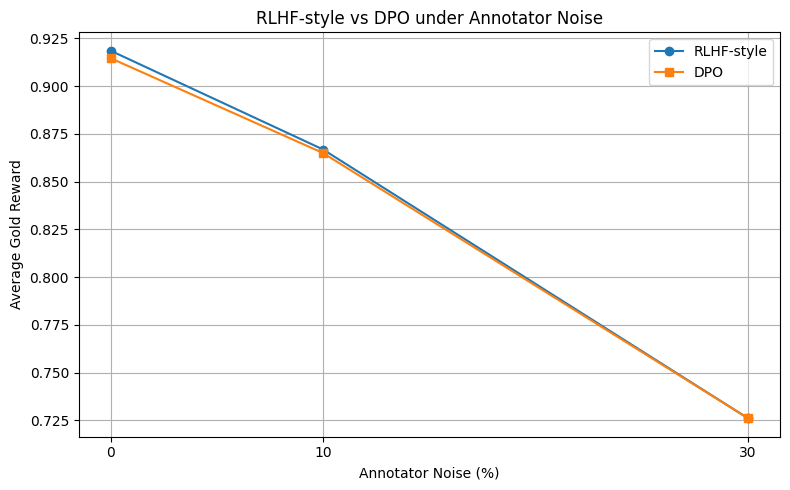

In [ ]:
summary_plot = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.plot(
    summary_plot.index * 100,
    summary_plot["RLHF Gold Reward"],
    marker="o",
    label="RLHF-style"
)

plt.plot(
    summary_plot.index * 100,
    summary_plot["DPO Gold Reward"],
    marker="s",
    label="DPO"
)

plt.xlabel("Annotator Noise (%)")
plt.ylabel("Average Gold Reward")
plt.title("RLHF-style vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Calculate average rewards at each noise level
summary = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .mean()
)

# Compare performance at 0% and 30% noise
for method in ["RLHF Gold Reward", "DPO Gold Reward"]:
    start = summary.loc[0.0, method]
    end = summary.loc[0.3, method]

    drop = start - end
    percentage_drop = (drop / start) * 100

    print(f"\n{method}")
    print(f"Reward at 0% noise:  {start:.4f}")
    print(f"Reward at 30% noise: {end:.4f}")
    print(f"Absolute decrease:   {drop:.4f}")
    print(f"Percentage decrease: {percentage_drop:.2f}%")

print("\nPerformance comparison completed!")


RLHF Gold Reward
Reward at 0% noise:  0.9186
Reward at 30% noise: 0.7261
Absolute decrease:   0.1925
Percentage decrease: 20.96%

DPO Gold Reward
Reward at 0% noise:  0.9147
Reward at 30% noise: 0.7261
Absolute decrease:   0.1886
Percentage decrease: 20.62%

Performance comparison completed!


In [ ]:
# Compare both methods for each noise level
results_df["Reward Difference"] = (
    results_df["RLHF Gold Reward"]
    - results_df["DPO Gold Reward"]
)

comparison = (
    results_df
    .groupby("Noise")["Reward Difference"]
    .agg(["mean", "std"])
    .round(5)
)

print("RLHF-style minus DPO:")
display(comparison)

print("\nPositive difference = RLHF-style performed better")
print("Negative difference = DPO performed better")
print("Zero difference = equal gold reward")

RLHF-style minus DPO:


,mean,std
Noise,,
0.0,0.00392,0.00014
0.1,0.00186,0.00052
0.3,0.00001,0.00000



Positive difference = RLHF-style performed better
Negative difference = DPO performed better
Zero difference = equal gold reward


In [ ]:
# Save all experimental results
results_df.to_csv(
    "rlhf_vs_dpo_results.csv",
    index=False
)

print("Results saved successfully!")
print("File: rlhf_vs_dpo_results.csv")
print("Total experiment records:", len(results_df))

Results saved successfully!
File: rlhf_vs_dpo_results.csv
Total experiment records: 60


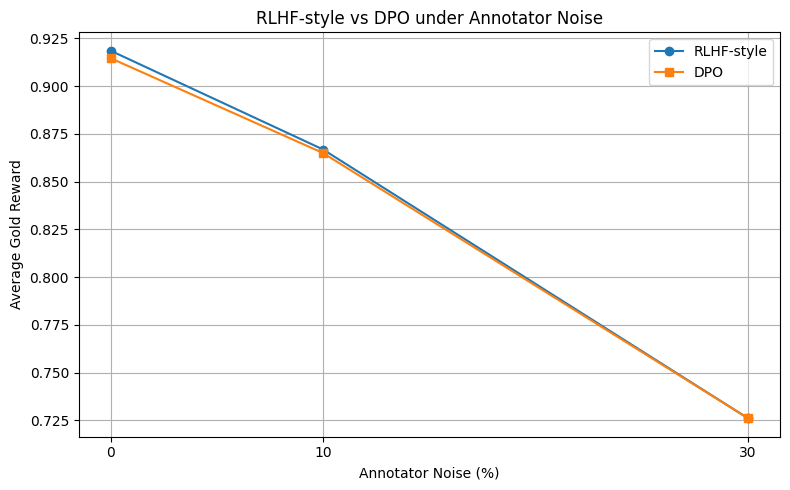

Graph saved successfully!
File: rlhf_vs_dpo_comparison.png


In [ ]:
# Calculate average rewards for plotting
summary_plot = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .mean()
)

# Create and save the graph
plt.figure(figsize=(8, 5))

plt.plot(
    summary_plot.index * 100,
    summary_plot["RLHF Gold Reward"],
    marker="o",
    label="RLHF-style"
)

plt.plot(
    summary_plot.index * 100,
    summary_plot["DPO Gold Reward"],
    marker="s",
    label="DPO"
)

plt.xlabel("Annotator Noise (%)")
plt.ylabel("Average Gold Reward")
plt.title("RLHF-style vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "rlhf_vs_dpo_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")
print("File: rlhf_vs_dpo_comparison.png")

In [ ]:
# Create a report-ready results table
report_table = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

report_table.columns = [
    "RLHF Mean",
    "RLHF Std",
    "DPO Mean",
    "DPO Std"
]

report_table.index = [
    "0% noise",
    "10% noise",
    "30% noise"
]

print("Final Results Table for Technical Report")
display(report_table)

Final Results Table for Technical Report


,RLHF Mean,RLHF Std,DPO Mean,DPO Std
0% noise,0.9186,0.0005,0.9147,0.0006
10% noise,0.8669,0.0099,0.8650,0.0094
30% noise,0.7261,0.0126,0.7261,0.0126
